# BIOT 6900 · Module 8 — Spatial Transcriptomics
## Toy notebook (1 of 3): a Visium tissue section, start to finish

This is a **run-and-read** notebook. There is no code for you to write. Open it in Jupyter, run **Kernel → Restart & Run All**, and read the explanation above each cell.

The single-cell toy taught you the standard pipeline. This one assumes that and spends its time on what is **new in space**: putting expression back on a tissue map and asking questions a dissociated dataset cannot.

- **Dataset:** a real **10x Visium** section (mouse brain, H&E), bundled with the `squidpy` package. Real data, not a simulation.
- **Focus:** the spatial toolkit from the lecture — spatial domains, spatially variable genes (Moran's I), neighborhood enrichment.
- **Compute:** CPU only. No GPU, no cluster. Internet is needed the first run to download the sample.
- **Maps to:** LO1, LO3.

> Toy (this notebook) → real-data notebook → the graded spatial assignment on your own disease.

### Before you run
Use the `biot6900` environment. Beyond the single-cell packages, this needs **`squidpy`** (which brings `scanpy` and `anndata` with it). If `import squidpy` fails, run the install cell once, then restart the kernel.

In [4]:
# Run once only if the import below fails, then restart the kernel.
# %pip install squidpy

In [5]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


scanpy 1.11.5 | squidpy 1.8.2


/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_1176/2839579529.py:9: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


## Step 1 · Load a real Visium section

`squidpy` ships a pre-processed 10x Visium H&E dataset. It is already normalized and clustered (the standard pipeline you ran in the single-cell toy), so here we go straight to the spatial analyses. The object carries three things single-cell never had: a **tissue image**, **spot coordinates**, and a **spatial graph** we will build.

In [6]:
adata = sq.datasets.visium_hne_adata()   # real 10x Visium mouse-brain section (downloads + caches on first run)
print(adata)
print("\nspatial coordinates per spot (obsm['spatial']):", adata.obsm["spatial"].shape)
print("precomputed clusters:", adata.obs["cluster"].nunique(), "spatial domains")

INFO     Downloading visium_hne_adata.h5ad from https://exampledata.scverse.org/squidpy/visium_hne_adata.h5ad      


/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


  0%|                                               | 0.00/329M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'leiden', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

spatial coordinates per spot (obsm['spatial']): (2688, 2)
precomputed clusters: 15 spatial domains


## Step 2 · The data object has a map

This is the one real difference from single-cell. Every spot keeps its `(x, y)` position in the tissue, and a registered H&E image sits underneath. Same `AnnData`, same `scanpy` habits, now with a coordinate system.

In [7]:
print("spots x genes:", adata.shape)
print("coordinate of the first five spots:")
print(adata.obsm["spatial"][:5])

spots x genes: (2688, 18078)
coordinate of the first five spots:
[[8230 7237]
 [4170 1611]
 [2519 8315]
 [7679 2927]
 [3138 6280]]


## Step 3 · Spatial domains: clusters now have a place

In single-cell, clusters floated in an abstract UMAP. Here we draw them back onto the tissue. Watch the clusters line up with real brain anatomy: that correspondence is the whole point of keeping the coordinates.

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/IPython/core/events.py:100: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


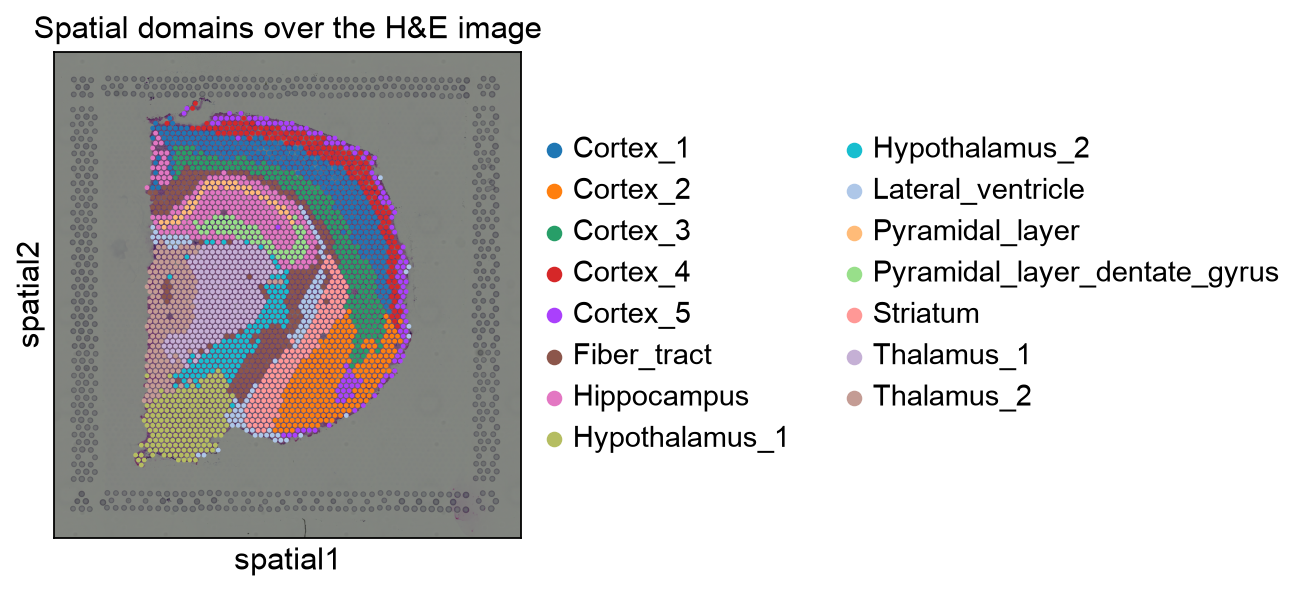

In [8]:
sq.pl.spatial_scatter(adata, color="cluster", size=1.3, title="Spatial domains over the H&E image")

## Step 4 · Spatially variable genes (Moran's I)

Some genes are expressed in a spatial pattern (a region, a layer) rather than scattered at random. We build a **spatial neighbor graph** (which spots touch which), then score every gene for spatial autocorrelation with **Moran's I**. High Moran's I means strongly patterned in space.

In [9]:
sq.gr.spatial_neighbors(adata)                 # who neighbors whom in the tissue
sq.gr.spatial_autocorr(adata, mode="moran")    # Moran's I per gene -> adata.uns["moranI"]

top_svg = adata.uns["moranI"].head(8)
print("Top spatially variable genes by Moran's I:")
print(top_svg[["I"]])

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_1176/1091460509.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata)                 # who neighbors whom in the tissue


Top spatially variable genes by Moran's I:
                I
Nrgn     0.874753
Mbp      0.868723
Camk2n1  0.866542
Slc17a7  0.861761
Ttr      0.841986
Prkcd    0.823550
Pmch     0.818155
Fth1     0.811259


Now plot the top few on the tissue. Each should paint a clear spatial region, not noise, which is exactly what a high Moran's I promised.

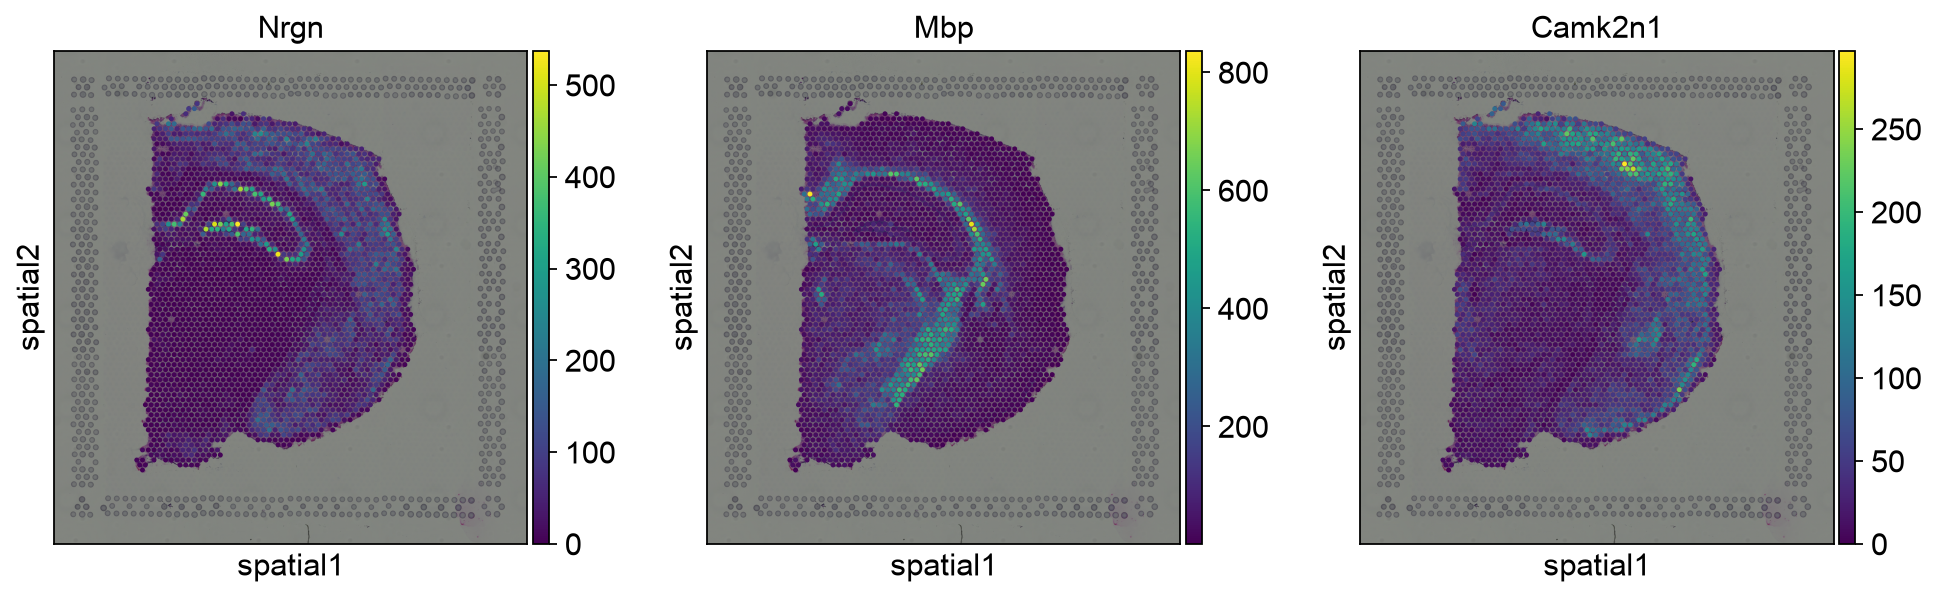

In [10]:
genes = adata.uns["moranI"].head(3).index.tolist()
sq.pl.spatial_scatter(adata, color=genes, size=1.3, ncols=3)

## Step 5 · Neighborhood enrichment: which domains sit together

Beyond "where is each domain", we can ask **which domains are neighbors more often than chance**. `nhood_enrichment` permutes the spatial graph and returns a z-score for every pair of clusters. Warm cells on the diagonal mean a domain clusters with itself; warm off-diagonal cells mean two domains interface.

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


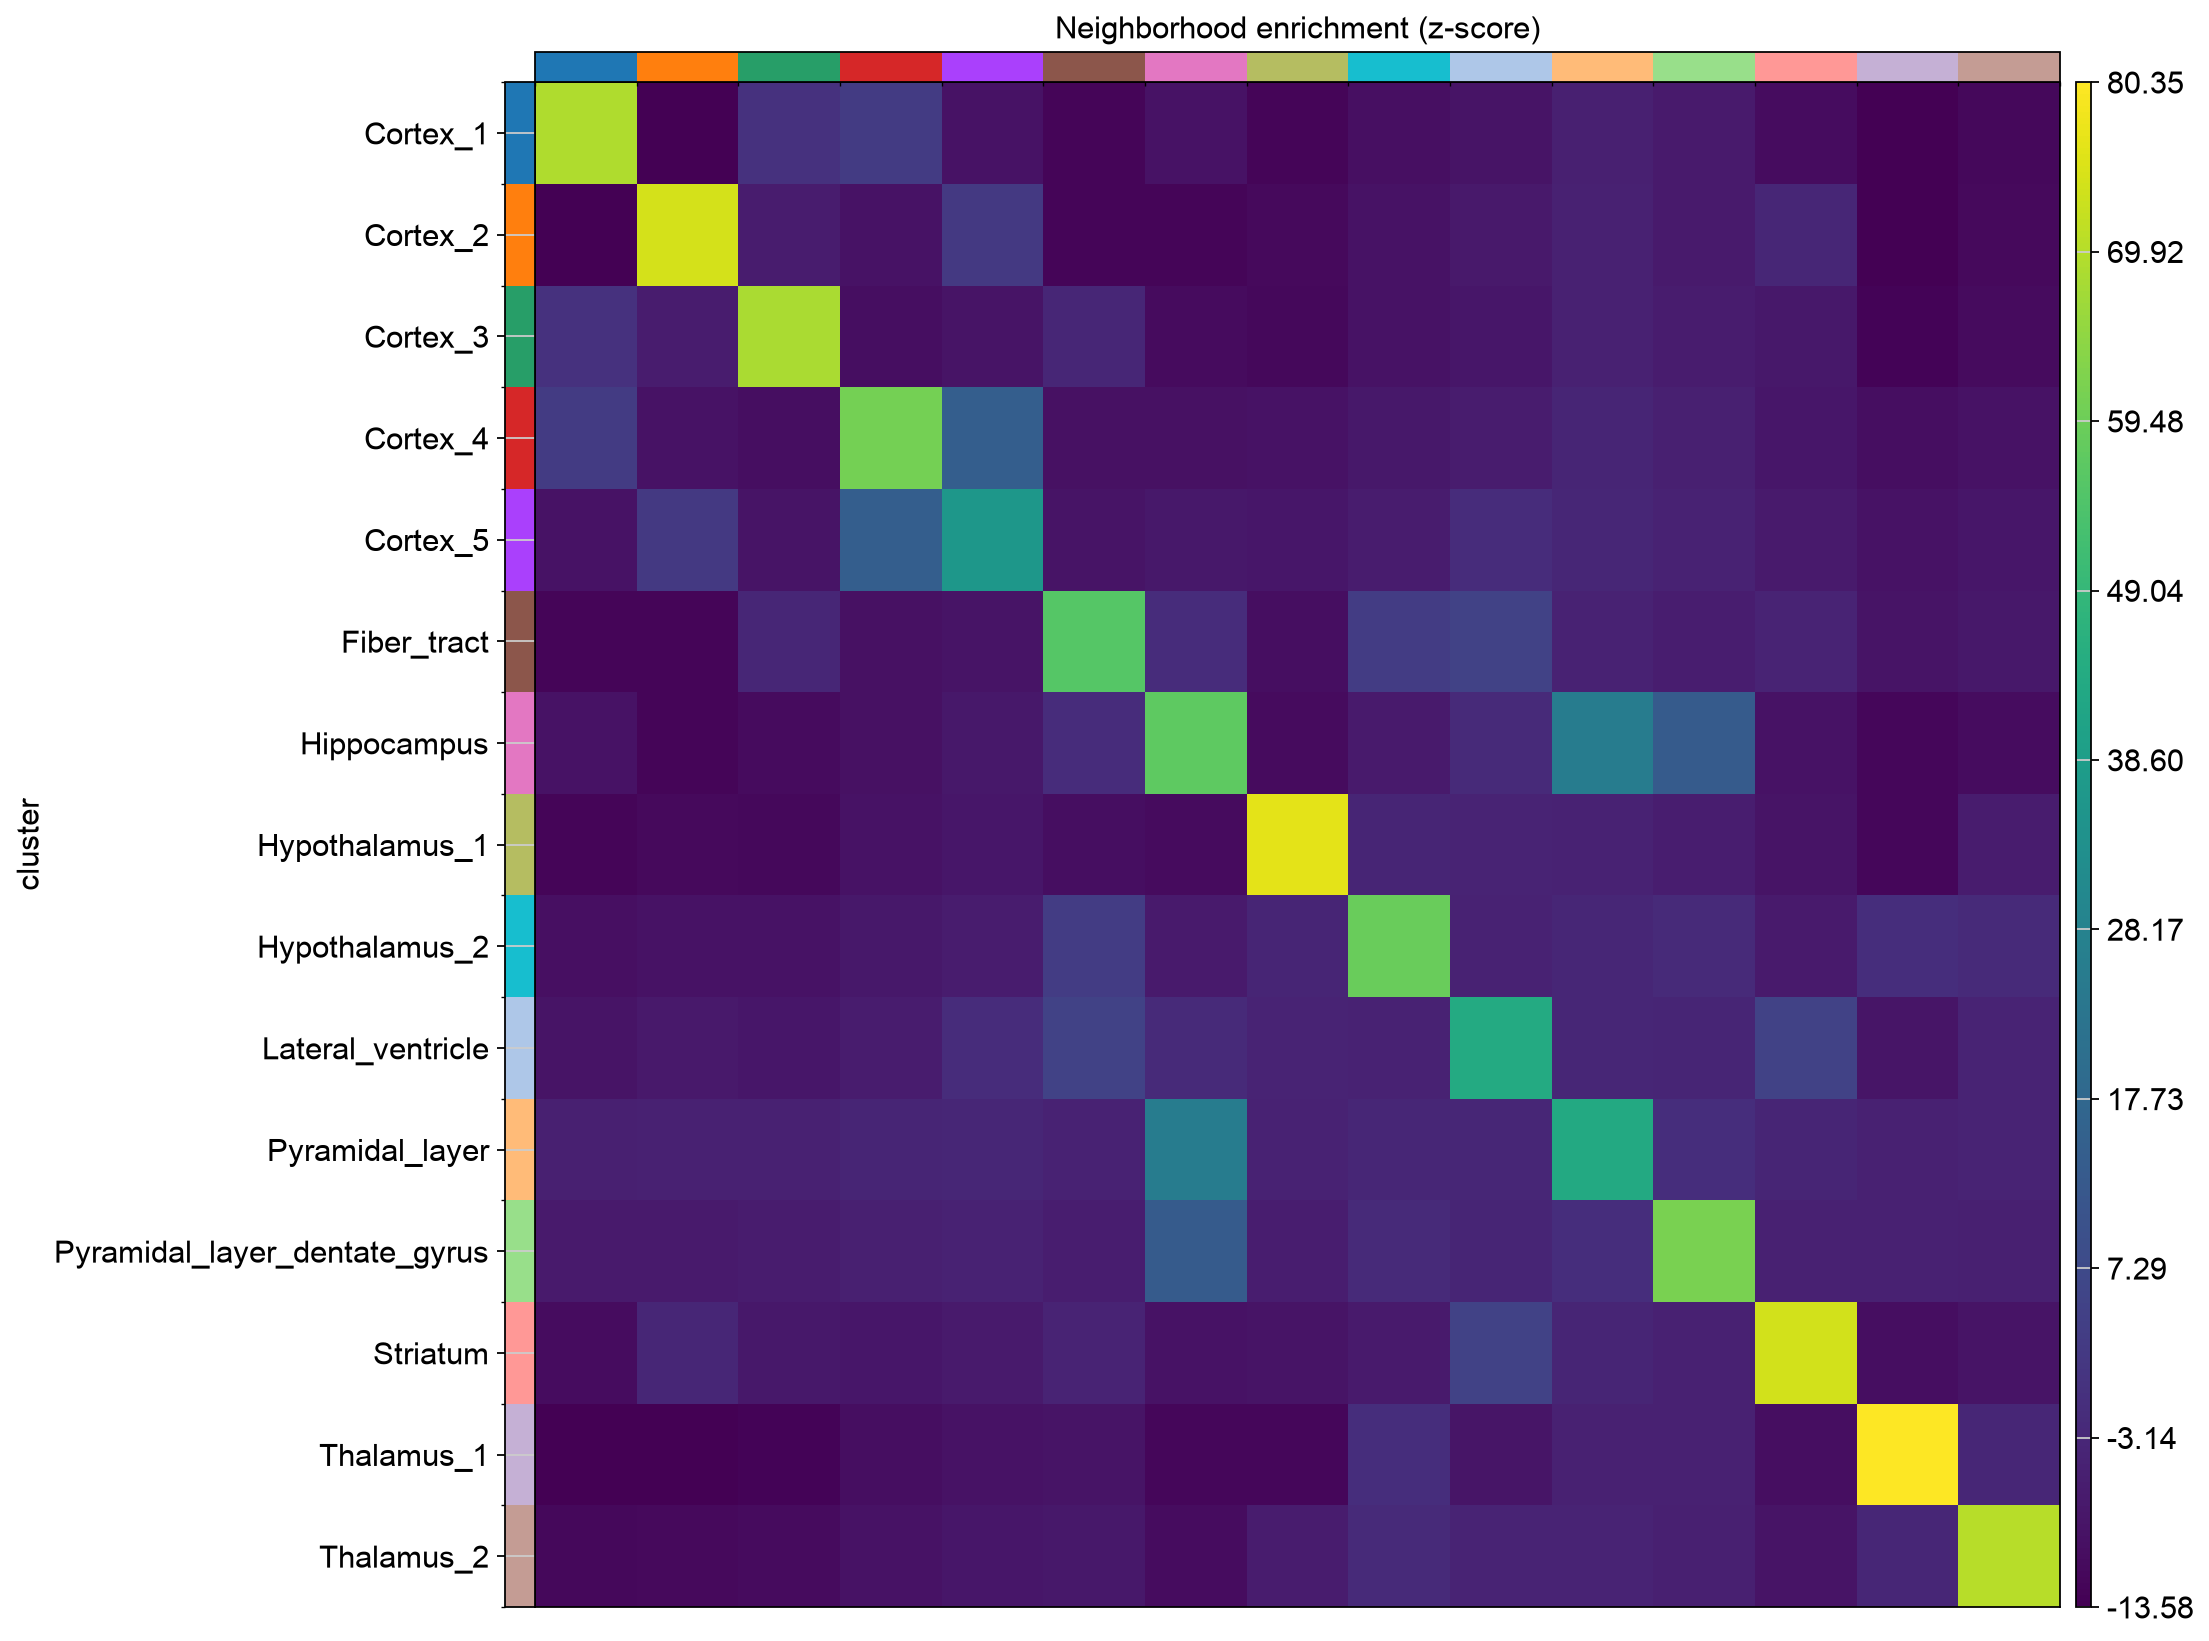

In [11]:
sq.gr.nhood_enrichment(adata, cluster_key="cluster")
sq.pl.nhood_enrichment(adata, cluster_key="cluster", title="Neighborhood enrichment (z-score)")

## Step 6 · A gene in space (the payoff)

Exactly the single-cell payoff, but now the answer is a *place*. Color the tissue by one gene and you can read off not just which cells express it, but **where** in the tissue they sit. In the graded assignment this gene is your own Part I target, on a section from your own disease.

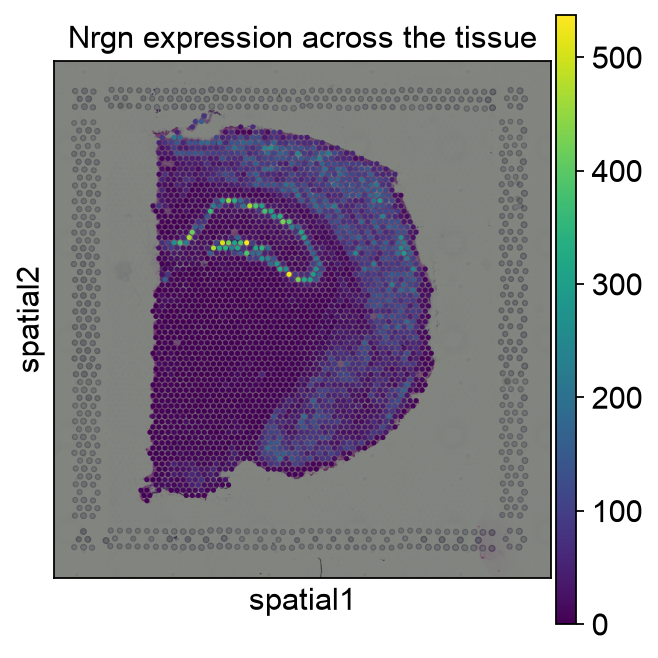

In [12]:
gene = adata.uns["moranI"].head(1).index[0]
sq.pl.spatial_scatter(adata, color=gene, size=1.3, title=f"{gene} expression across the tissue")

## What you just saw

- A Visium section is the familiar `AnnData`, plus **coordinates** and a **tissue image**.
- Drawing clusters onto the tissue turns abstract domains into **anatomy**.
- **Moran's I** finds genes with real spatial structure; **neighborhood enrichment** shows which domains interface.
- Coloring the tissue by a gene answers *where* it is expressed, the spatial version of the single-cell payoff.

**Next:** the real-data notebook works a disease-relevant section and connects spots back to single-cell cell types (deconvolution). Then the graded spatial assignment runs this workflow on your own disease.